In [1]:
   %pip install -q fastapi uvicorn httpx pydantic joblib scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
###Import library###
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
###Load data###
df_raw = pd.read_csv("sets.csv")   # ganti path jika file ada di folder lain

print("Shape :", df_raw.shape)
display(df_raw.head())
print()
df_raw.info()

Shape : (14936, 17)


,Set_ID,Name,Year,Theme,Theme_Group,Subtheme,Category,Packaging,Num_Instructions,Availability,Pieces,Minifigures,Owned,Rating,USD_MSRP,Total_Quantity,Current_Price
0,75-1,PreSchool Set,1975,PreSchool,Pre-school,NaN,Normal,{Not specified},0,{Not specified},16.0,NaN,10.0,0.0,NaN,NaN,NaN
1,77-1,PreSchool Set,1975,PreSchool,Pre-school,NaN,Normal,{Not specified},0,{Not specified},20.0,NaN,11.0,0.0,NaN,NaN,NaN
2,077-1,Pre-School Set,1975,Duplo,Pre-school,NaN,Normal,{Not specified},0,{Not specified},21.0,NaN,10.0,0.0,NaN,0.0,NaN
3,78-1,PreSchool Set,1975,PreSchool,Pre-school,NaN,Normal,{Not specified},0,{Not specified},32.0,NaN,8.0,0.0,NaN,NaN,NaN
4,78-3,Basic Set,1975,Samsonite,Vintage,Basic set,Normal,Box,0,{Not specified},330.0,NaN,10.0,0.0,NaN,0.0,NaN



<class 'pandas.DataFrame'>
RangeIndex: 14936 entries, 0 to 14935
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Set_ID            14936 non-null  str    
 1   Name              14936 non-null  str    
 2   Year              14936 non-null  int64  
 3   Theme             14936 non-null  str    
 4   Theme_Group       14915 non-null  str    
 5   Subtheme          11495 non-null  str    
 6   Category          14936 non-null  str    
 7   Packaging         14936 non-null  str    
 8   Num_Instructions  14936 non-null  int64  
 9   Availability      14936 non-null  str    
 10  Pieces            13133 non-null  float64
 11  Minifigures       7686 non-null   float64
 12  Owned             14771 non-null  float64
 13  Rating            14936 non-null  float64
 14  USD_MSRP          5837 non-null   float64
 15  Total_Quantity    12276 non-null  float64
 16  Current_Price     5442 non-null   float64
dtypes: 

In [4]:
#Ringkasan awal
display(df_raw.describe(include="all").T)

print("Jumlah duplikat baris   :", df_raw.duplicated().sum())
print("Jumlah duplikat Set_ID  :", df_raw["Set_ID"].duplicated().sum())

missing = (df_raw.isna().sum().to_frame("missing")
           .assign(pct=lambda d: (d["missing"] / len(df_raw) * 100).round(2))
           .sort_values("missing", ascending=False))
display(missing[missing["missing"] > 0])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Set_ID,14936,14936,75-1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,14936,12372,Bonus/Value Pack,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,14936.0,NaN,NaN,NaN,2006.750736,11.524612,1975.0,2000.0,2009.0,2016.0,2023.0
Theme,14936,155,Duplo,1278,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Theme_Group,14915,16,Miscellaneous,3407,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Subtheme,11495,783,Product Collection,378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,14936,7,Normal,12586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Packaging,14936,17,Box,6880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Num_Instructions,14936.0,NaN,NaN,NaN,1.196036,2.087763,0.0,0.0,0.0,2.0,48.0
Availability,14936,10,Retail,6475,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Jumlah duplikat baris   : 0
Jumlah duplikat Set_ID  : 0


,missing,pct
Current_Price,9494,63.56
USD_MSRP,9099,60.92
Minifigures,7250,48.54
Subtheme,3441,23.04
Total_Quantity,2660,17.81
Pieces,1803,12.07
Owned,165,1.10
Theme_Group,21,0.14


In [5]:
###Data cleaning###
df = df_raw.copy()

# 4.1 Samakan placeholder "tidak diketahui" menjadi satu label
for col in ["Packaging", "Availability"]:
    df[col] = df[col].replace({"{Not specified}": "Unknown"})

# 4.2 Missing value kategorikal
df["Theme_Group"] = df["Theme_Group"].fillna("Unknown")
df["Subtheme"] = df["Subtheme"].fillna("None")

# 4.3 Pieces = 0 tidak masuk akal untuk sebuah set -> anggap missing
df["Pieces"] = df["Pieces"].replace(0, np.nan)

# 4.4 Minifigures kosong = set tanpa minifigure (nilai minimum di data = 1)
df["Minifigures"] = df["Minifigures"].fillna(0)

# 4.5 Rapikan teks
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# 4.6 Pastikan tipe data
df["Year"] = df["Year"].astype(int)

print("Sisa missing value:")
display(df.isna().sum()[df.isna().sum() > 0].to_frame("missing"))

Sisa missing value:


,missing
Pieces,1815
Owned,165
USD_MSRP,9099
Total_Quantity,2660
Current_Price,9494


In [6]:
###Transformation (feature engineering)###
CURRENT_YEAR = df["Year"].max()

# Nomor varian dari Set_ID, contoh "75-1" -> 1
df["Set_Variant"] = pd.to_numeric(df["Set_ID"].str.split("-").str[-1], errors="coerce")

# Umur set & dekade rilis
df["Age"] = CURRENT_YEAR - df["Year"]
df["Decade"] = (df["Year"] // 10 * 10).astype(str) + "s"

# Flag sederhana
df["Has_Minifig"] = (df["Minifigures"] > 0).astype(int)
df["Has_Rating"] = (df["Rating"] > 0).astype(int)      # Rating 0 = belum ada rating

# Rasio harga retail per keping (hanya jika MSRP & Pieces tersedia)
df["MSRP_per_Piece"] = df["USD_MSRP"] / df["Pieces"]

# Transformasi log untuk fitur yang sangat skewed
for col in ["Pieces", "Owned", "USD_MSRP", "Current_Price"]:
    df[f"log_{col}"] = np.log1p(df[col])

display(df.head())

,Set_ID,Name,Year,Theme,Theme_Group,Subtheme,Category,Packaging,Num_Instructions,Availability,Pieces,Minifigures,Owned,Rating,USD_MSRP,Total_Quantity,Current_Price,Set_Variant,Age,Decade,Has_Minifig,Has_Rating,MSRP_per_Piece,log_Pieces,log_Owned,log_USD_MSRP,log_Current_Price
0,75-1,PreSchool Set,1975,PreSchool,Pre-school,None,Normal,Unknown,0,Unknown,16.0,0.0,10.0,0.0,NaN,NaN,NaN,1,48,1970s,0,0,NaN,2.833213,2.397895,NaN,NaN
1,77-1,PreSchool Set,1975,PreSchool,Pre-school,None,Normal,Unknown,0,Unknown,20.0,0.0,11.0,0.0,NaN,NaN,NaN,1,48,1970s,0,0,NaN,3.044522,2.484907,NaN,NaN
2,077-1,Pre-School Set,1975,Duplo,Pre-school,None,Normal,Unknown,0,Unknown,21.0,0.0,10.0,0.0,NaN,0.0,NaN,1,48,1970s,0,0,NaN,3.091042,2.397895,NaN,NaN
3,78-1,PreSchool Set,1975,PreSchool,Pre-school,None,Normal,Unknown,0,Unknown,32.0,0.0,8.0,0.0,NaN,NaN,NaN,1,48,1970s,0,0,NaN,3.496508,2.197225,NaN,NaN
4,78-3,Basic Set,1975,Samsonite,Vintage,Basic set,Normal,Box,0,Unknown,330.0,0.0,10.0,0.0,NaN,0.0,NaN,3,48,1970s,0,0,NaN,5.802118,2.397895,NaN,NaN


In [7]:
###EDA dan Eksplorasi Data###
#Statistik deskriptif
num_cols = ["Year", "Pieces", "Minifigures", "Owned", "Rating",
            "Num_Instructions", "USD_MSRP", "Total_Quantity", "Current_Price"]

display(df[num_cols].describe().T)
print("Skewness:")
display(df[num_cols].skew().round(2).to_frame("skew").T)

,count,mean,std,min,25%,50%,75%,max
Year,14936.0,2006.750736,11.524612,1975.00,2000.00,2009.00,2016.00,2023.00
Pieces,13121.0,238.153342,473.252180,1.00,25.00,81.00,262.00,11695.00
Minifigures,14936.0,1.394483,2.515725,0.00,0.00,1.00,2.00,80.00
Owned,14771.0,2045.236951,2972.330218,1.00,90.00,744.00,2828.50,29429.00
Rating,14936.0,1.826627,1.950909,0.00,0.00,0.00,3.90,4.90
Num_Instructions,14936.0,1.196036,2.087763,0.00,0.00,0.00,2.00,48.00
USD_MSRP,5837.0,39.967050,55.006213,1.49,9.99,19.99,49.99,849.99
Total_Quantity,12276.0,4.708618,20.995961,0.00,0.00,0.00,3.00,1063.00
Current_Price,5442.0,90.164663,193.452605,0.05,15.00,36.00,92.00,5499.99


Skewness:


,Year,Pieces,Minifigures,Owned,Rating,Num_Instructions,USD_MSRP,Total_Quantity,Current_Price
skew,-0.69,7.22,5.93,2.48,0.16,4.36,4.67,18.94,11.26


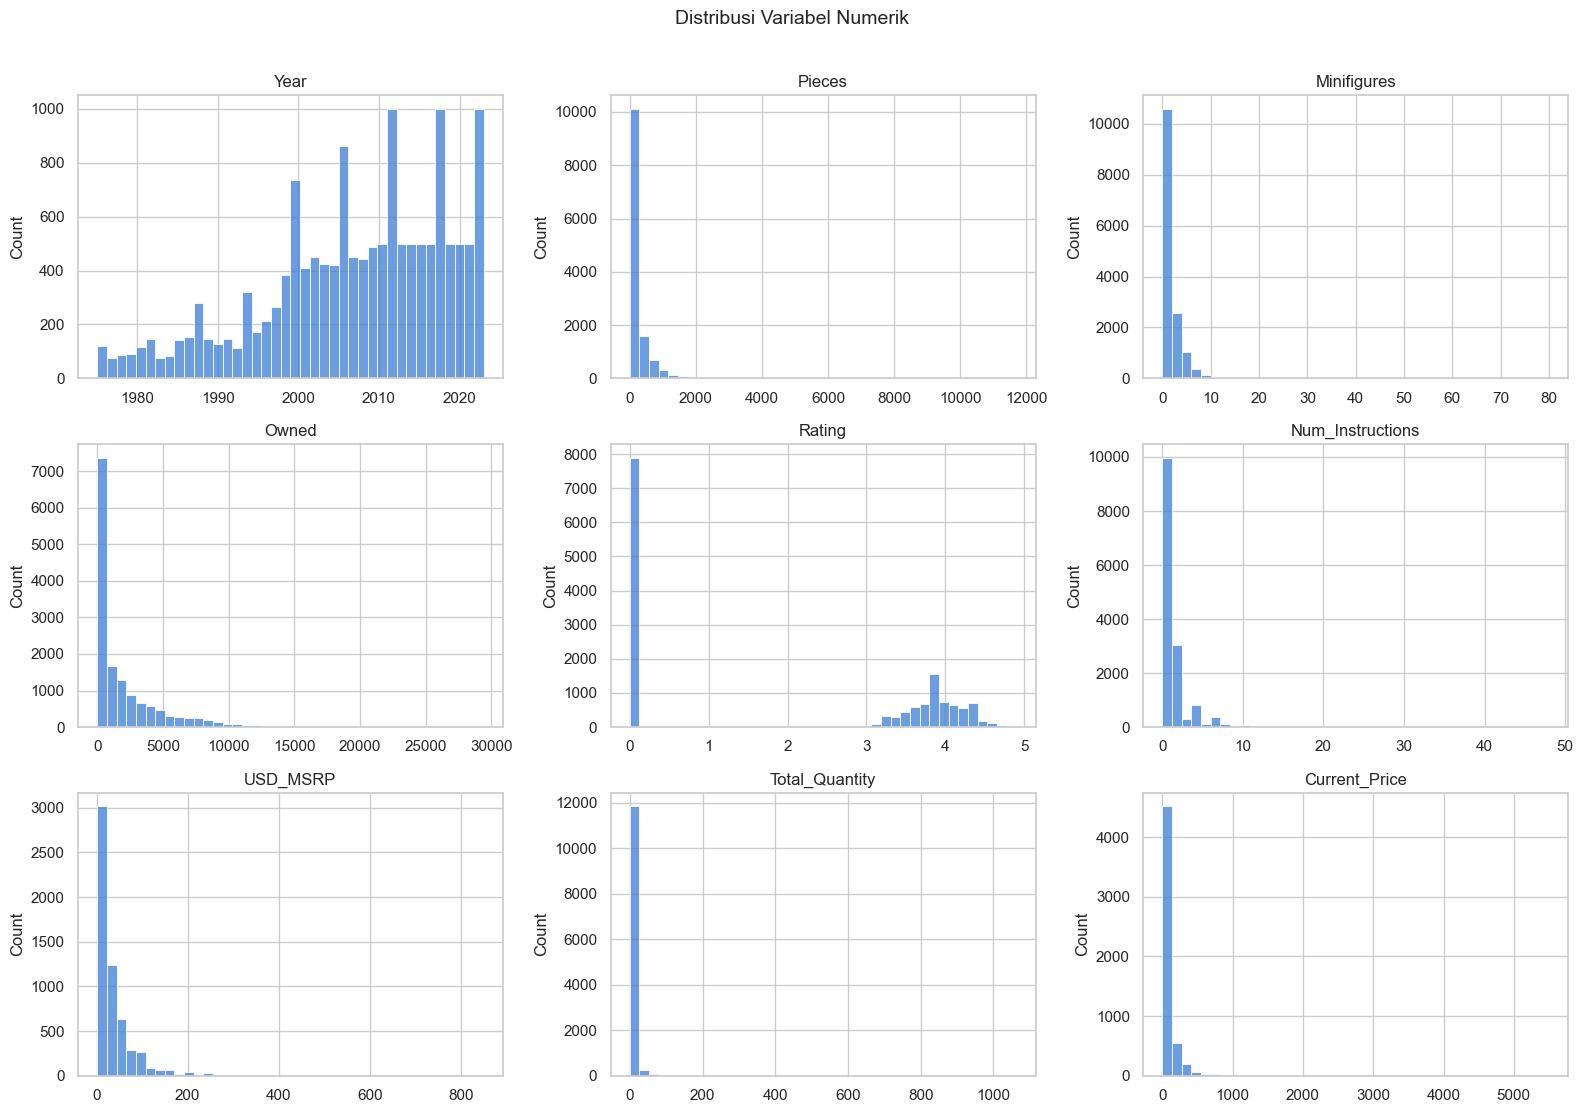

In [8]:
#Distribusi numerik
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col].dropna(), bins=40, kde=False, ax=ax, color="#3b7dd8")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribusi Variabel Numerik", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

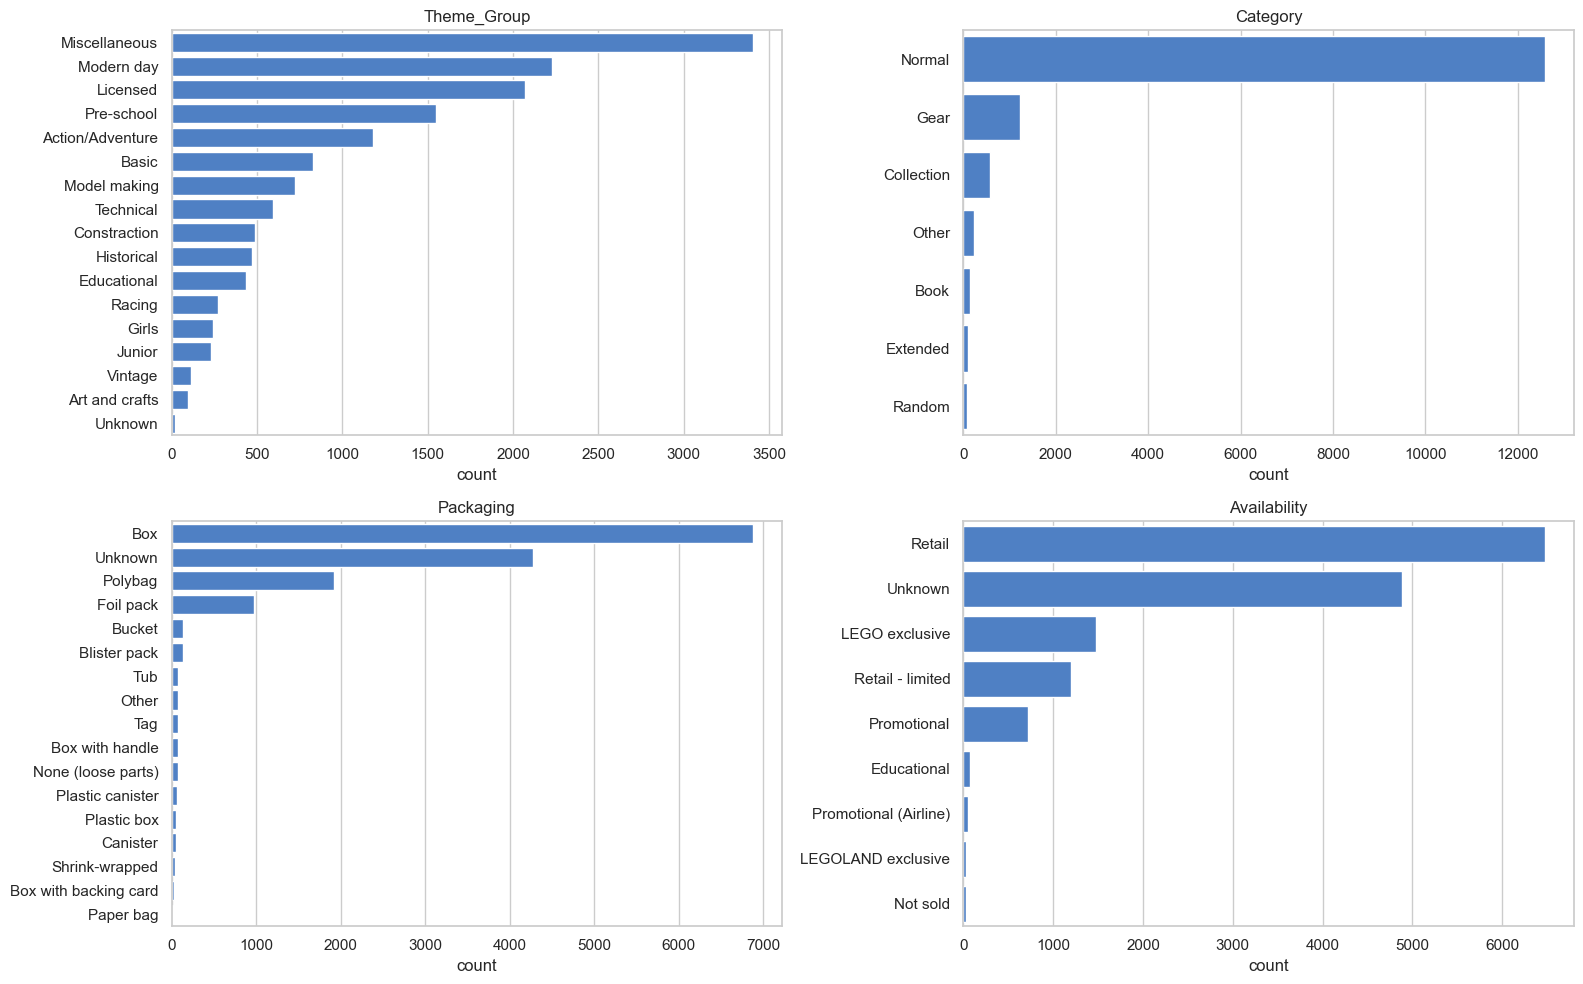

Top 15 Theme:


,jumlah_set
Theme,
Duplo,1278
Gear,1232
Collectable Minifigures,804
City,770
Star Wars,723
Town,648
Creator,528
Technic,481
Friends,429


In [9]:
#Variabel kategorikal
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.ravel(), ["Theme_Group", "Category", "Packaging", "Availability"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax, color="#3b7dd8")
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("Top 15 Theme:")
display(df["Theme"].value_counts().head(15).to_frame("jumlah_set"))

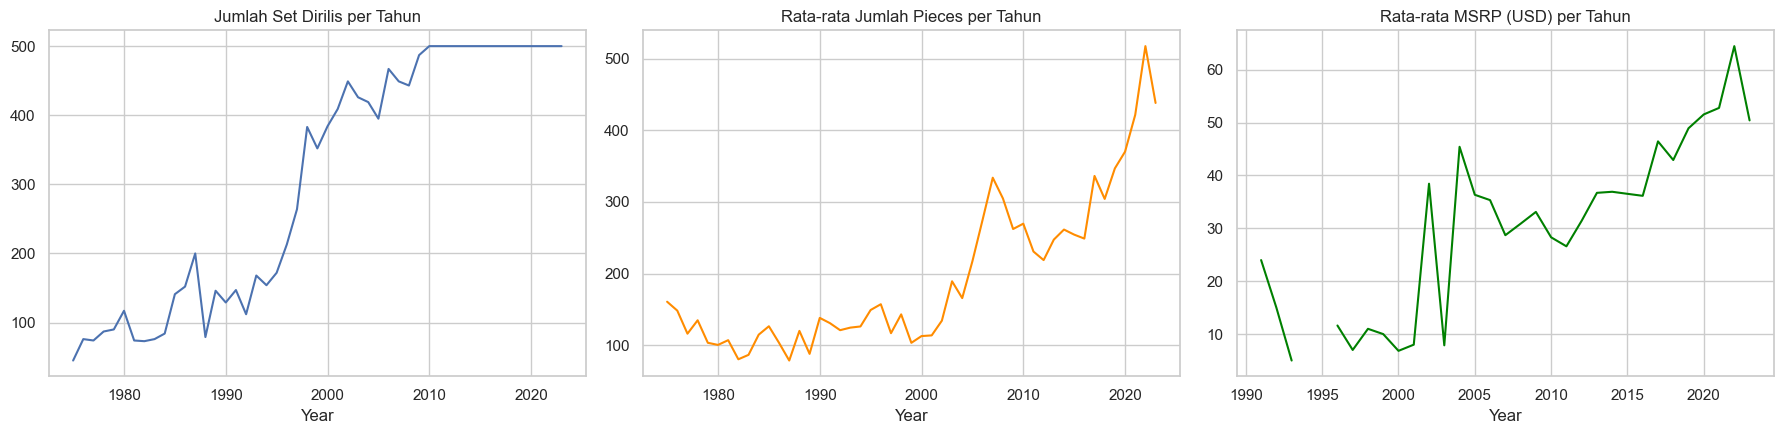

In [10]:
#Tren per tahun
yearly = df.groupby("Year").agg(jumlah_set=("Set_ID", "count"),
                                rata2_pieces=("Pieces", "mean"),
                                rata2_msrp=("USD_MSRP", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
yearly["jumlah_set"].plot(ax=axes[0], title="Jumlah Set Dirilis per Tahun")
yearly["rata2_pieces"].plot(ax=axes[1], title="Rata-rata Jumlah Pieces per Tahun", color="darkorange")
yearly["rata2_msrp"].plot(ax=axes[2], title="Rata-rata MSRP (USD) per Tahun", color="green")
plt.tight_layout()
plt.show()

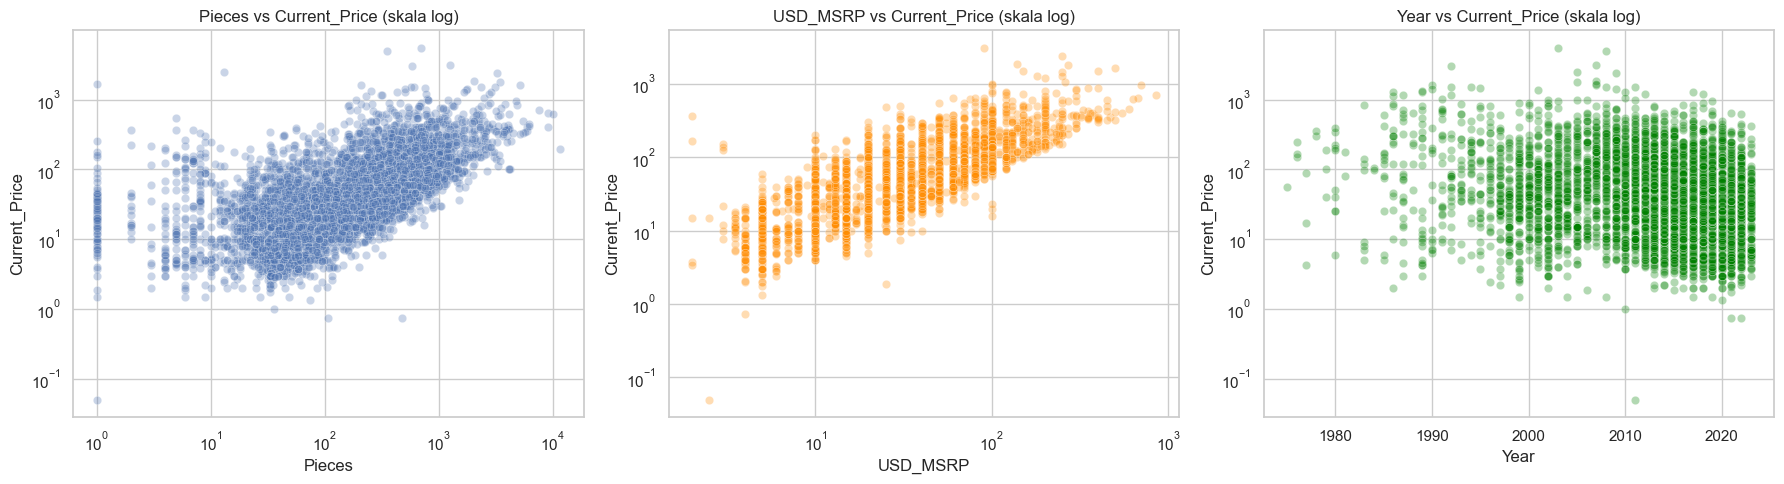

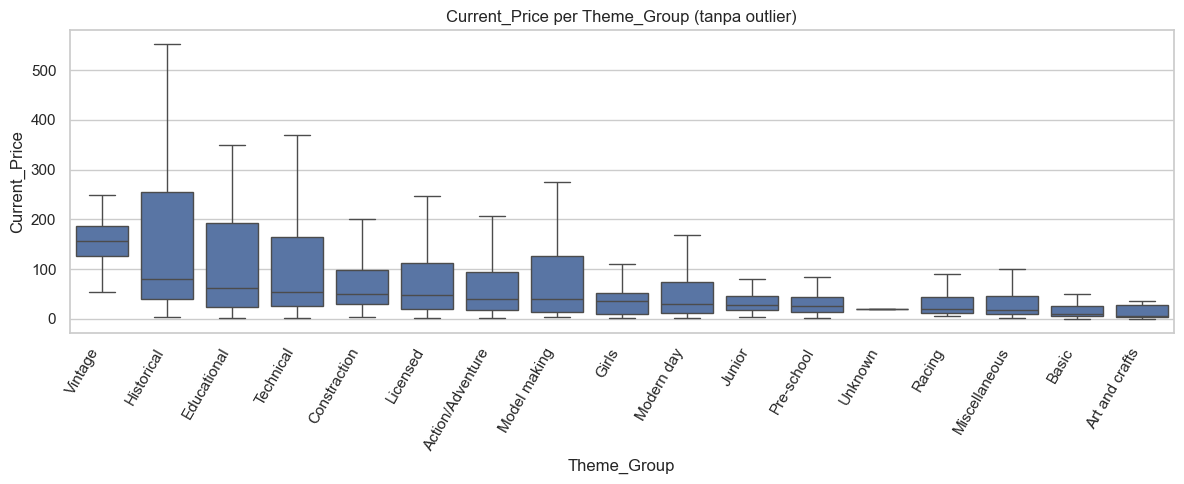

In [11]:
#Hubungan fitur dengan harga (bivariat)
price_df = df[df["Current_Price"].notna()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=price_df, x="Pieces", y="Current_Price", alpha=0.3, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Pieces vs Current_Price (skala log)")

sns.scatterplot(data=price_df, x="USD_MSRP", y="Current_Price", alpha=0.3, ax=axes[1], color="darkorange")
axes[1].set(xscale="log", yscale="log", title="USD_MSRP vs Current_Price (skala log)")

sns.scatterplot(data=price_df, x="Year", y="Current_Price", alpha=0.3, ax=axes[2], color="green")
axes[2].set(yscale="log", title="Year vs Current_Price (skala log)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
order = price_df.groupby("Theme_Group")["Current_Price"].median().sort_values(ascending=False).index
sns.boxplot(data=price_df, x="Theme_Group", y="Current_Price", order=order, showfliers=False)
plt.xticks(rotation=60, ha="right")
plt.title("Current_Price per Theme_Group (tanpa outlier)")
plt.tight_layout()
plt.show()

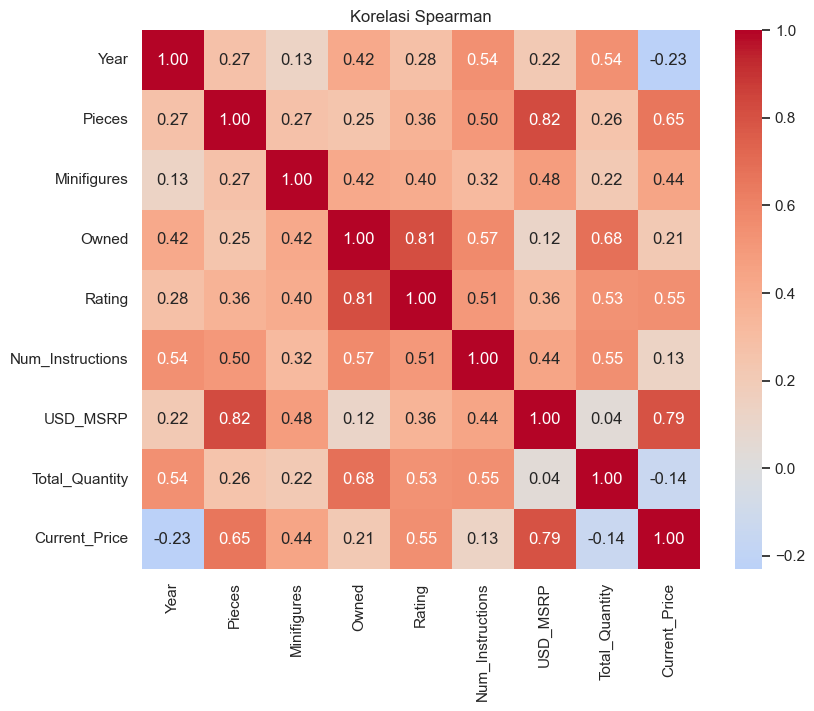

In [12]:
#Korelasi (multivariat)
corr_cols = ["Year", "Pieces", "Minifigures", "Owned", "Rating", "Num_Instructions",
             "USD_MSRP", "Total_Quantity", "Current_Price"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Spearman")
plt.show()

,n_outlier,pct
Pieces,1295,9.9
Owned,1163,7.9
USD_MSRP,363,6.2
Current_Price,545,10.0


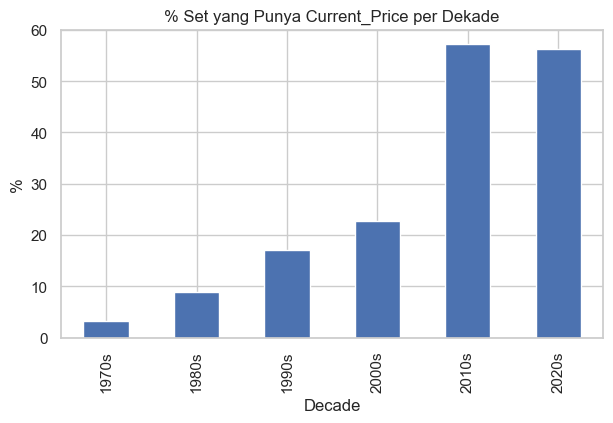

In [13]:
#Outlier dan pola missing
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_tbl = pd.DataFrame({
    "n_outlier": {c: iqr_outliers(df[c]) for c in ["Pieces", "Owned", "USD_MSRP", "Current_Price"]},
})
outlier_tbl["pct"] = (outlier_tbl["n_outlier"] / df[["Pieces", "Owned", "USD_MSRP", "Current_Price"]].notna().sum()
                      * 100).round(1)
display(outlier_tbl)

# Apakah ketersediaan harga bergantung pada tahun rilis?
df.assign(has_price=df["Current_Price"].notna()).groupby("Decade")["has_price"].mean().mul(100).round(1).plot(
    kind="bar", title="% Set yang Punya Current_Price per Dekade", figsize=(7, 4))
plt.ylabel("%")
plt.show()

In [14]:
###Data Processing###
#Tentukan target dan fitur
# Target : Current_Price (harga pasar saat ini), dimodelkan dalam skala log
# Hanya baris yang punya target yang bisa dipakai untuk supervised learning
model_df = df[df["Current_Price"].notna()].copy()
print("Baris dengan target:", model_df.shape[0], "dari", df.shape[0])

target = "log_Current_Price"

numeric_features = ["Year", "Age", "Set_Variant", "Pieces", "Minifigures", "Owned", "Rating",
                    "Num_Instructions", "USD_MSRP", "MSRP_per_Piece", "Total_Quantity",
                    "Has_Minifig", "Has_Rating"]
categorical_features = ["Theme", "Theme_Group", "Category", "Packaging", "Availability"]

# Dibuang: Set_ID & Name (identifier / teks bebas), Subtheme (kardinalitas tinggi),
# Current_Price & log_Current_Price (target / kebocoran data)
X = model_df[numeric_features + categorical_features]
y = model_df[target]

print("X:", X.shape, "| y:", y.shape)

Baris dengan target: 5442 dari 14936
X: (5442, 18) | y: (5442,)


In [15]:
#Preprocessing pipeline
# Imputasi & scaling dilakukan di dalam pipeline agar hanya "belajar" dari data train (anti data leakage)
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),   # tambah flag kolom yang di-impute
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False)),  # kategori jarang -> "infrequent"
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [16]:
###Data Splitting###
#Train/test split
# Kurangi bias pembagian dengan menstratifikasi berdasarkan kuantil target
y_bins = pd.qcut(y, q=5, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bins
)

print(f"Train : {X_train.shape}  | Test : {X_test.shape}")
print("Rata-rata target (log) -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train : (4353, 18)  | Test : (1089, 18)
Rata-rata target (log) -> train: 3.693 | test: 3.694


In [17]:
#Perbandingan model (5-fold cross-validation)
models = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    cv_results.append({"model": name, "CV_RMSE(log)": rmse.mean(), "CV_RMSE_std": rmse.std(), "CV_R2": r2.mean()})

cv_df = pd.DataFrame(cv_results).sort_values("CV_RMSE(log)").reset_index(drop=True)
display(cv_df.round(4))

,model,CV_RMSE(log),CV_RMSE_std,CV_R2
0,HistGradientBoosting,0.4919,0.0054,0.8394
1,RandomForest,0.5080,0.0054,0.8288
2,Ridge,0.6727,0.0356,0.6984


In [18]:
#Hyperparameter tuning
best_name = cv_df.loc[0, "model"]
print("Model terbaik di CV:", best_name)

hgb_pipe = Pipeline([("prep", preprocessor),
                     ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))])

param_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_iter": [200, 400, 600],
    "model__max_depth": [None, 4, 6, 8],
    "model__min_samples_leaf": [10, 20, 40],
    "model__l2_regularization": [0.0, 0.1, 1.0],
}

search = RandomizedSearchCV(hgb_pipe, param_dist, n_iter=15, cv=cv,
                            scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

print("Best params :", search.best_params_)
print("Best CV RMSE:", round(-search.best_score_, 4))
final_model = search.best_estimator_

Model terbaik di CV: HistGradientBoosting
Best params : {'model__min_samples_leaf': 10, 'model__max_iter': 400, 'model__max_depth': None, 'model__learning_rate': 0.03, 'model__l2_regularization': 1.0}
Best CV RMSE: 0.4849


In [19]:
#Evaluasi pada data test
def evaluate(model, X_, y_, label):
    pred_log = model.predict(X_)
    pred, actual = np.expm1(pred_log), np.expm1(y_)          # kembalikan ke USD
    return {
        "set": label,
        "RMSE(log)": np.sqrt(mean_squared_error(y_, pred_log)),
        "R2(log)": r2_score(y_, pred_log),
        "MAE(USD)": mean_absolute_error(actual, pred),
        "RMSE(USD)": np.sqrt(mean_squared_error(actual, pred)),
    }

eval_df = pd.DataFrame([evaluate(final_model, X_train, y_train, "train"),
                        evaluate(final_model, X_test, y_test, "test")])
display(eval_df.round(3))

# Pembanding: tebak selalu median harga train
baseline_pred = np.full(len(y_test), y_train.median())
print("Baseline (median) RMSE(log):", round(np.sqrt(mean_squared_error(y_test, baseline_pred)), 4))

,set,RMSE(log),R2(log),MAE(USD),RMSE(USD)
0,train,0.333,0.927,23.119,85.507
1,test,0.481,0.851,37.587,161.870


Baseline (median) RMSE(log): 1.2496


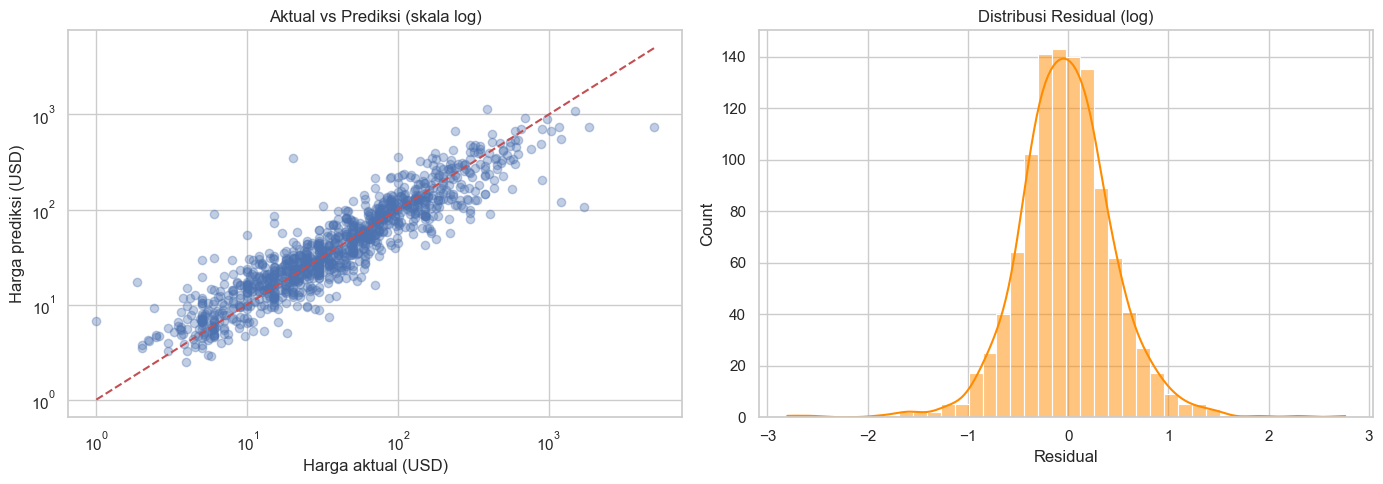

In [20]:
#Visualisasi hasil
pred_log = final_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(np.expm1(y_test), np.expm1(pred_log), alpha=0.35)
lim = [1, max(np.expm1(y_test).max(), np.expm1(pred_log).max())]
axes[0].plot(lim, lim, "r--")
axes[0].set(xscale="log", yscale="log", xlabel="Harga aktual (USD)", ylabel="Harga prediksi (USD)",
            title="Aktual vs Prediksi (skala log)")

residual = y_test - pred_log
sns.histplot(residual, bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].set(title="Distribusi Residual (log)", xlabel="Residual")
plt.tight_layout()
plt.show()

,fitur,importance,std
3,Pieces,0.5454,0.0114
0,Year,0.2227,0.0087
6,Rating,0.1245,0.0089
16,Packaging,0.1131,0.0069
8,USD_MSRP,0.0988,0.0066
14,Theme_Group,0.0525,0.0056
4,Minifigures,0.0487,0.0071
13,Theme,0.0439,0.0038
2,Set_Variant,0.0395,0.0011
10,Total_Quantity,0.0250,0.0047


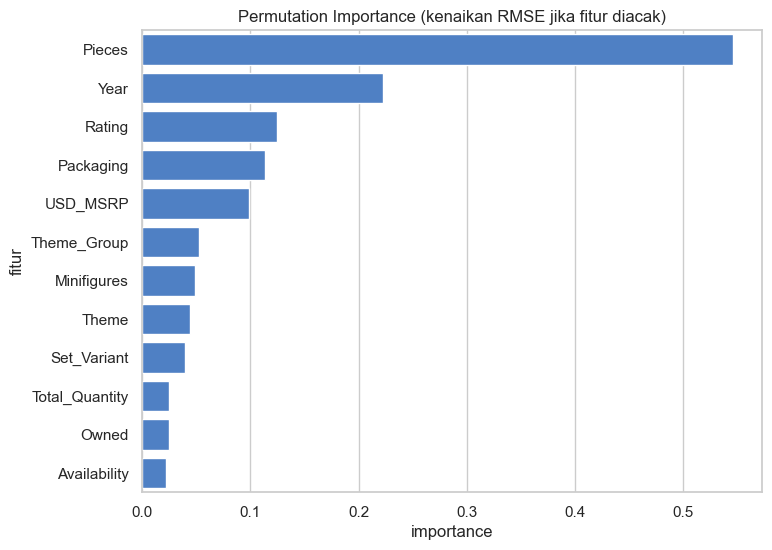

In [21]:
#Feature importance
perm = permutation_importance(final_model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error", n_jobs=-1)

imp = (pd.DataFrame({"fitur": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
       .sort_values("importance", ascending=False))
display(imp.round(4))

plt.figure(figsize=(8, 6))
sns.barplot(data=imp.head(12), x="importance", y="fitur", color="#3b7dd8")
plt.title("Permutation Importance (kenaikan RMSE jika fitur diacak)")
plt.show()

# Deployment

Alur: **simpan artefak model → bungkus feature engineering → API (FastAPI) → uji → container (Docker)**.

Poin penting: model dilatih pada fitur hasil *feature engineering* (`Age`, `Set_Variant`, `MSRP_per_Piece`, dst.), jadi service harus menerima **data mentah** dan menghitung fitur itu sendiri dengan logika yang identik. Karena itu logika tersebut dipisah ke `lego_features.py` dan diuji kesamaannya dengan hasil di notebook.

In [22]:
###Deployment: persiapan folder###
import os, sys, json, shutil, joblib, platform, importlib
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
import sklearn

DEPLOY_DIR = Path("deployment")
ART_DIR = DEPLOY_DIR / "artifacts"
ART_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(DEPLOY_DIR.resolve()))

**1. Modul feature engineering untuk inference** (ditulis ke `deployment/lego_features.py`)

In [23]:
%%writefile deployment/lego_features.py
"""Feature engineering untuk inference. Harus identik dengan yang dipakai saat training."""
import numpy as np
import pandas as pd

RAW_COLUMNS = ["Set_ID", "Year", "Theme", "Theme_Group", "Category", "Packaging",
               "Num_Instructions", "Availability", "Pieces", "Minifigures", "Owned",
               "Rating", "USD_MSRP", "Total_Quantity"]

NUMERIC_FEATURES = ["Year", "Age", "Set_Variant", "Pieces", "Minifigures", "Owned", "Rating",
                    "Num_Instructions", "USD_MSRP", "MSRP_per_Piece", "Total_Quantity",
                    "Has_Minifig", "Has_Rating"]
CATEGORICAL_FEATURES = ["Theme", "Theme_Group", "Category", "Packaging", "Availability"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES


def _clean_text(v):
    return v.strip() if isinstance(v, str) else np.nan


def prepare_features(raw: pd.DataFrame, current_year: int) -> pd.DataFrame:
    """Raw kolom sets.csv -> fitur siap masuk pipeline model.

    current_year HARUS nilai yang dibekukan saat training (bukan tahun hari ini),
    kalau tidak fitur Age akan bergeser sendiri.
    """
    df = raw.reindex(columns=RAW_COLUMNS).copy()

    for col in ["Set_ID"] + CATEGORICAL_FEATURES:
        df[col] = df[col].map(_clean_text).astype(object)
    for col in ["Packaging", "Availability"]:
        df[col] = df[col].replace({"{Not specified}": "Unknown"})
    df["Theme_Group"] = df["Theme_Group"].fillna("Unknown")

    for col in ["Year", "Pieces", "Minifigures", "Owned", "Rating",
                "Num_Instructions", "USD_MSRP", "Total_Quantity"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Pieces"] = df["Pieces"].replace(0, np.nan)
    df["Minifigures"] = df["Minifigures"].fillna(0)

    df["Set_Variant"] = pd.to_numeric(df["Set_ID"].str.split("-").str[-1], errors="coerce")
    df["Age"] = current_year - df["Year"]
    df["Has_Minifig"] = (df["Minifigures"] > 0).astype(int)
    df["Has_Rating"] = (df["Rating"] > 0).astype(int)
    df["MSRP_per_Piece"] = df["USD_MSRP"] / df["Pieces"]

    return df[FEATURE_COLUMNS]

Overwriting deployment/lego_features.py


In [24]:
###Uji kesamaan fitur: serving vs training###
import lego_features as lf
importlib.reload(lf)

X_serving = lf.prepare_features(df_raw.loc[model_df.index], current_year=CURRENT_YEAR)

# 1) Fitur hasil modul harus sama persis dengan X yang dipakai saat training
pd.testing.assert_frame_equal(X, X_serving, check_dtype=False, check_exact=False, rtol=1e-9)
# 2) Prediksi harus identik
assert np.allclose(final_model.predict(X), final_model.predict(X_serving))
print("OK - fitur & prediksi di serving identik dengan di notebook.")
print("CURRENT_YEAR yang dibekukan untuk Age:", CURRENT_YEAR)

OK - fitur & prediksi di serving identik dengan di notebook.
CURRENT_YEAR yang dibekukan untuk Age: 2023


**2. Simpan artefak.** Yang disimpan bukan hanya model, tapi juga: metadata (versi, metrik, parameter, versi library), rentang residual untuk interval prediksi, dan statistik data training sebagai **referensi monitoring**.

In [25]:
###Simpan model, metadata, dan statistik referensi###
import monitoring as mon
importlib.reload(mon)

test_pred_log = final_model.predict(X_test)
resid = y_test - test_pred_log
baseline_rmse = float(np.sqrt(mean_squared_error(y_test, baseline_pred)))
test_row = eval_df[eval_df["set"] == "test"].iloc[0]

metadata = {
    "model_version": "1.0.0",
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "algorithm": "HistGradientBoostingRegressor (dalam sklearn Pipeline)",
    "target": "log1p(Current_Price USD); output API sudah di-expm1 ke USD",
    "current_year": int(CURRENT_YEAR),
    "features_numeric": lf.NUMERIC_FEATURES,
    "features_categorical": lf.CATEGORICAL_FEATURES,
    "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "metrics_test": {"rmse_log": float(test_row["RMSE(log)"]), "r2_log": float(test_row["R2(log)"]),
                     "mae_usd": float(test_row["MAE(USD)"]), "rmse_usd": float(test_row["RMSE(USD)"]),
                     "baseline_rmse_log": baseline_rmse},
    # Interval 80% empiris dari residual test (skala log): y ~ pred + residual
    "residual_q10": float(resid.quantile(0.10)), "residual_q90": float(resid.quantile(0.90)),
    "runtime": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                "pandas": pd.__version__, "numpy": np.__version__},
    "limitations": ["Hanya set yang punya Current_Price saat training",
                    "Set dengan tema/kategori baru ditangani sebagai 'infrequent'",
                    "Interval 80% bersifat empiris, bukan jaminan"],
}

joblib.dump(final_model, ART_DIR / "lego_price_model.joblib", compress=3)
(ART_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))

reference = mon.build_reference(X_train, lf.NUMERIC_FEATURES, lf.CATEGORICAL_FEATURES)
(ART_DIR / "reference_stats.json").write_text(json.dumps(reference))

# requirements dipin ke versi yang dipakai saat training (pickle sklearn sensitif terhadap versi)
req = [f"scikit-learn=={sklearn.__version__}", f"pandas=={pd.__version__}", f"numpy=={np.__version__}",
       f"joblib=={version('joblib')}", f"scipy=={version('scipy')}",
       f"fastapi=={version('fastapi')}", f"uvicorn[standard]=={version('uvicorn')}",
       f"pydantic=={version('pydantic')}"]
(DEPLOY_DIR / "requirements.txt").write_text("\n".join(req) + "\n")

# Smoke test: model hasil load dari disk harus memberi prediksi yang sama
loaded = joblib.load(ART_DIR / "lego_price_model.joblib")
assert np.allclose(loaded.predict(X_test), test_pred_log)

print({p.name: f"{p.stat().st_size/1024:.0f} KB" for p in ART_DIR.iterdir()})
print("Interval 80% (log):", round(metadata["residual_q10"], 3), "s/d", round(metadata["residual_q90"], 3))

{'lego_price_model.joblib': '575 KB', 'model_metadata.json': '1 KB', 'reference_stats.json': '8 KB'}
Interval 80% (log): -0.541 s/d 0.54


**3. API service** (`deployment/app.py`): `/predict`, `/predict/batch`, `/feedback` (harga aktual untuk monitoring), `/health`. Setiap prediksi dicatat ke log JSONL.

In [26]:
%%writefile deployment/app.py
"""FastAPI service untuk prediksi harga set LEGO.
Jalankan:  uvicorn app:app --host 0.0.0.0 --port 8000
"""
import json
import os
import threading
import uuid
from datetime import datetime, timezone
from pathlib import Path
from typing import List, Optional

import joblib
import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from lego_features import FEATURE_COLUMNS, prepare_features

BASE = Path(__file__).parent
LOG_DIR = Path(os.getenv("LOG_DIR", BASE / "logs"))
LOG_DIR.mkdir(parents=True, exist_ok=True)

model = joblib.load(BASE / "artifacts" / "lego_price_model.joblib")
meta = json.loads((BASE / "artifacts" / "model_metadata.json").read_text())
_lock = threading.Lock()

app = FastAPI(title="LEGO Price Predictor", version=meta["model_version"])


class LegoSet(BaseModel):
    Set_ID: str = Field(..., min_length=1, examples=["75192-1"])
    Year: int = Field(..., ge=1949, le=2100)
    Theme: Optional[str] = None
    Theme_Group: Optional[str] = None
    Category: Optional[str] = None
    Packaging: Optional[str] = None
    Availability: Optional[str] = None
    Num_Instructions: Optional[float] = Field(None, ge=0)
    Pieces: Optional[float] = Field(None, ge=0)
    Minifigures: Optional[float] = Field(None, ge=0)
    Owned: Optional[float] = Field(None, ge=0)
    Rating: Optional[float] = Field(None, ge=0, le=5)
    USD_MSRP: Optional[float] = Field(None, ge=0)
    Total_Quantity: Optional[float] = Field(None, ge=0)


class Feedback(BaseModel):
    request_id: str
    actual_price_usd: float = Field(..., gt=0)


def _append(name, record):
    with _lock, open(LOG_DIR / name, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, default=str) + "\n")


def _predict(items: List[LegoSet]):
    raw = pd.DataFrame([i.model_dump() for i in items])
    X = prepare_features(raw, meta["current_year"])
    pred_log = model.predict(X)
    out = []
    for (_, row), pl in zip(X.iterrows(), pred_log):
        rid = uuid.uuid4().hex
        price = float(np.expm1(pl))
        low = float(max(np.expm1(pl + meta["residual_q10"]), 0))
        high = float(np.expm1(pl + meta["residual_q90"]))
        _append("predictions.jsonl", {
            "request_id": rid, "ts": datetime.now(timezone.utc).isoformat(),
            "model_version": meta["model_version"],
            "features": {k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v))
                         for k, v in row.items()},
            "pred_log": float(pl), "pred_price_usd": price})
        out.append({"request_id": rid, "predicted_price_usd": round(price, 2),
                    "interval_80pct_usd": [round(low, 2), round(high, 2)],
                    "model_version": meta["model_version"]})
    return out


@app.get("/health")
def health():
    return {"status": "ok", "model_version": meta["model_version"],
            "trained_at": meta["trained_at"]}


@app.post("/predict")
def predict(item: LegoSet):
    return _predict([item])[0]


@app.post("/predict/batch")
def predict_batch(items: List[LegoSet]):
    if not 0 < len(items) <= 1000:
        raise HTTPException(422, "Batch harus berisi 1-1000 item")
    return _predict(items)


@app.post("/feedback")
def feedback(fb: Feedback):
    """Kirim harga aktual setelah diketahui -> dipakai untuk monitoring performa."""
    _append("actuals.jsonl", {"request_id": fb.request_id, "actual_price_usd": fb.actual_price_usd,
                              "ts": datetime.now(timezone.utc).isoformat()})
    return {"status": "recorded"}

Overwriting deployment/app.py


**4. Containerisasi** (`Dockerfile`)

In [27]:
%%writefile deployment/Dockerfile
FROM python:3.12-slim
WORKDIR /srv
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py lego_features.py monitoring.py ./
COPY artifacts ./artifacts
ENV LOG_DIR=/srv/logs
VOLUME /srv/logs
EXPOSE 8000
HEALTHCHECK CMD python -c "import urllib.request as u; u.urlopen('http://localhost:8000/health')" || exit 1
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

Overwriting deployment/Dockerfile


**5. Uji API** memakai `TestClient` (tanpa perlu menjalankan server). Log uji ditulis ke `logs_demo/` agar tidak bercampur dengan log produksi.

In [28]:
###Uji endpoint API###
os.environ["LOG_DIR"] = str(DEPLOY_DIR / "logs_demo")
shutil.rmtree(os.environ["LOG_DIR"], ignore_errors=True)

import app as lego_app
importlib.reload(lego_app)
from fastapi.testclient import TestClient
client = TestClient(lego_app.app)

def to_payload(row):
    """Baris data mentah -> JSON body (NaN jadi null)."""
    return {k: (None if pd.isna(row[k]) else (row[k].item() if hasattr(row[k], "item") else row[k]))
            for k in lf.RAW_COLUMNS}

print("GET /health ->", client.get("/health").json())

idx0 = X_test.index[0]
sample = df_raw.loc[idx0]
r = client.post("/predict", json=to_payload(sample))
print("\nPOST /predict ->", r.status_code, r.json())
print(f"Harga aktual untuk set {sample['Set_ID']} ({sample['Name']}): ${sample['Current_Price']:.2f}")

# Validasi input: Year tidak masuk akal harus ditolak (422), bukan menghasilkan prediksi ngawur
bad = client.post("/predict", json={"Set_ID": "x-1", "Year": 1800})
print("\nInput tidak valid ->", bad.status_code)

# Set dengan data minim (hanya Set_ID & Year) tetap bisa diprediksi lewat imputasi di pipeline
print("Input minimal    ->", client.post("/predict", json={"Set_ID": "99999-1", "Year": 2020}).json()["predicted_price_usd"])

# Kirim feedback harga aktual (nanti dipakai monitoring performa)
fb = client.post("/feedback", json={"request_id": r.json()["request_id"], "actual_price_usd": float(sample["Current_Price"])})
print("POST /feedback ->", fb.json())

GET /health -> {'status': 'ok', 'model_version': '1.0.0', 'trained_at': '2026-10-15T07:19:32+00:00'}

POST /predict -> 200 {'request_id': 'da438d5caf3d4dcfb21963f524baab5c', 'predicted_price_usd': 6.57, 'interval_80pct_usd': [3.41, 11.99], 'model_version': '1.0.0'}
Harga aktual untuk set 40211-1 (Bee): $10.26

Input tidak valid -> 422
Input minimal    -> 19.95
POST /feedback -> {'status': 'recorded'}


**Menjalankan sendiri:**
```bash
cd deployment
pip install -r requirements.txt
uvicorn app:app --port 8000            # lalu buka http://localhost:8000/docs
# atau lewat Docker
docker build -t lego-price-api . && docker run -p 8000:8000 -v $(pwd)/logs:/srv/logs lego-price-api
```

# Monitoring

Setelah model live, ada tiga hal yang dipantau:

1. **Data quality & data drift** — apakah data yang masuk masih mirip data training? (PSI per fitur, missing rate, kategori baru)
2. **Performa model** — apakah error naik? Butuh harga aktual, yang biasanya datang terlambat (lewat `/feedback`).
3. **Keputusan** — kapan cukup *WARN*, kapan harus *retrain*.

Modul `monitoring.py` menyediakan semuanya.

In [29]:
%%writefile deployment/monitoring.py
"""Utilitas monitoring: data quality, drift (PSI), performa model, dan keputusan alert."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

EPS = 1e-4
PSI_WARN, PSI_ALERT = 0.10, 0.25          # konvensi umum industri
MISSING_DELTA_WARN = 0.10                 # kenaikan missing rate > 10 poin persentase
UNSEEN_CAT_WARN = 0.05                    # >5% nilai kategori belum pernah terlihat


def _psi(ref_p, cur_p):
    ref_p = np.clip(np.asarray(ref_p, float), EPS, None)
    cur_p = np.clip(np.asarray(cur_p, float), EPS, None)
    ref_p, cur_p = ref_p / ref_p.sum(), cur_p / cur_p.sum()
    return float(np.sum((cur_p - ref_p) * np.log(cur_p / ref_p)))


def _status(psi):
    return "ALERT" if psi >= PSI_ALERT else "WARN" if psi >= PSI_WARN else "OK"


def build_reference(X, numeric, categorical, min_share=0.02):
    """Ringkasan distribusi data training -> dict (disimpan sebagai JSON)."""
    ref = {"n_rows": int(len(X)), "numeric": {}, "categorical": {}}
    for c in numeric:
        s = X[c].dropna().astype(float)
        edges = np.unique(np.quantile(s, np.linspace(0, 1, 11)))
        inner = edges[1:-1]
        if len(inner) < 2:        # fitur biner / hampir konstan: pakai nilai unik sebagai bin
            vals = np.sort(s.value_counts().head(10).index.values.astype(float))
            inner = (vals[:-1] + vals[1:]) / 2 if len(vals) > 1 else np.array([])
        counts = np.bincount(np.digitize(s, inner), minlength=len(inner) + 1)
        ref["numeric"][c] = {"inner_edges": inner.tolist(),
                             "bin_props": (counts / counts.sum()).tolist(),
                             "missing_rate": float(X[c].isna().mean()),
                             "mean": float(s.mean()), "p01": float(s.quantile(.01)),
                             "p99": float(s.quantile(.99))}
    for c in categorical:
        vc = X[c].fillna("Unknown").value_counts()
        known = vc[vc / len(X) >= min_share]   # <=~50 bin; bin terlalu banyak membuat PSI berisik
        props = (known / len(X)).to_dict()
        props["__other__"] = float(1 - sum(props.values()))
        ref["categorical"][c] = {"props": props, "all_values": vc.index.tolist(),
                                 "missing_rate": float(X[c].isna().mean())}
    return ref


def drift_report(batch, ref):
    rows = []
    for c, r in ref["numeric"].items():
        s = pd.to_numeric(batch[c], errors="coerce")
        v = s.dropna()
        if len(v) == 0 or len(r["inner_edges"]) == 0:
            psi = np.nan
        else:
            counts = np.bincount(np.digitize(v, r["inner_edges"]), minlength=len(r["bin_props"]))
            psi = _psi(r["bin_props"], counts / counts.sum())
        rows.append({"feature": c, "type": "numeric", "psi": psi,
                     "missing_rate": float(s.isna().mean()),
                     "missing_delta": float(s.isna().mean() - r["missing_rate"]),
                     "unseen_rate": np.nan,
                     "out_of_range_rate": float(((v < r["p01"]) | (v > r["p99"])).mean()) if len(v) else np.nan})
    for c, r in ref["categorical"].items():
        s = batch[c].fillna("Unknown")
        known_all = set(r["all_values"])
        mapped = s.where(s.isin(r["props"].keys()), "__other__")
        keys = list(r["props"].keys())
        cur = mapped.value_counts(normalize=True).reindex(keys).fillna(0).values
        rows.append({"feature": c, "type": "categorical",
                     "psi": _psi([r["props"][k] for k in keys], cur),
                     "missing_rate": float(batch[c].isna().mean()),
                     "missing_delta": float(batch[c].isna().mean() - r["missing_rate"]),
                     "unseen_rate": float((~s.isin(known_all)).mean()),
                     "out_of_range_rate": np.nan})
    out = pd.DataFrame(rows)
    out["status"] = out["psi"].map(lambda p: "n/a" if pd.isna(p) else _status(p))
    flag = (out["missing_delta"] > MISSING_DELTA_WARN) | (out["unseen_rate"] > UNSEEN_CAT_WARN)
    out.loc[flag & (out["status"] == "OK"), "status"] = "WARN"
    return out.sort_values("psi", ascending=False).reset_index(drop=True)


def performance_report(y_true_log, y_pred_log):
    y_true_log, y_pred_log = np.asarray(y_true_log), np.asarray(y_pred_log)
    res = y_true_log - y_pred_log
    return {"n": int(len(res)),
            "rmse_log": float(np.sqrt(np.mean(res ** 2))),
            "bias_log": float(res.mean()),                     # >0 = model under-predict
            "resid_sd": float(res.std(ddof=1)) if len(res) > 1 else 0.0,
            "mae_usd": float(np.mean(np.abs(np.expm1(y_true_log) - np.expm1(y_pred_log))))}


LEVELS = ["OK", "WARN", "ALERT", "RETRAIN"]


def overall_status(drift_df, perf, baseline_rmse_log, rmse_warn=1.10, rmse_alert=1.25,
                   bias_warn=0.10, bias_alert=0.25, min_n=30):
    """Satu keputusan ringkas: OK < WARN < ALERT (investigasi) < RETRAIN.

    - Drift fitur saja -> maksimal ALERT: drift belum tentu menurunkan akurasi, perlu dikonfirmasi harga aktual.
    - Performa turun (RMSE naik, atau bias sistematis yang signifikan) -> RETRAIN.
    - Performa mulai turun + drift berat -> RETRAIN.
    Bias dicek terpisah karena RMSE kurang sensitif terhadap pergeseran harga yang seragam.
    """
    reasons, lvl = [], 0
    n_alert = int((drift_df["status"] == "ALERT").sum())
    n_warn = int((drift_df["status"] == "WARN").sum())
    if n_alert:
        lvl = 2; reasons.append(f"{n_alert} fitur drift berat (PSI>={PSI_ALERT})")
    if n_warn:
        lvl = max(lvl, 1); reasons.append(f"{n_warn} fitur drift ringan/data quality")

    perf_lvl = 0
    if perf is not None and perf["n"] >= min_n:
        ratio = perf["rmse_log"] / baseline_rmse_log
        se = perf.get("resid_sd", 0) / np.sqrt(perf["n"]) if perf.get("resid_sd") else np.inf
        bias_sig = abs(perf["bias_log"]) / se >= 3          # bias harus signifikan secara statistik
        if ratio >= rmse_alert:
            perf_lvl = 2; reasons.append(f"RMSE(log) {ratio:.2f}x baseline")
        elif ratio >= rmse_warn:
            perf_lvl = 1; reasons.append(f"RMSE(log) {ratio:.2f}x baseline")
        if bias_sig and abs(perf["bias_log"]) >= bias_alert:
            perf_lvl = 2; reasons.append(f"bias {perf['bias_log']:+.2f} (log) signifikan")
        elif bias_sig and abs(perf["bias_log"]) >= bias_warn:
            perf_lvl = max(perf_lvl, 1); reasons.append(f"bias {perf['bias_log']:+.2f} (log) signifikan")

    if perf_lvl == 2 or (perf_lvl == 1 and n_alert):
        lvl = 3
    elif perf_lvl == 1:
        lvl = max(lvl, 1)
    return {"status": LEVELS[lvl], "reasons": reasons}


def load_logs(log_dir):
    """Gabungkan log prediksi + feedback aktual (join lewat request_id)."""
    log_dir = Path(log_dir)
    def _read(p):
        if not p.exists():
            return pd.DataFrame()
        return pd.DataFrame([json.loads(l) for l in p.read_text().splitlines() if l.strip()])
    preds, acts = _read(log_dir / "predictions.jsonl"), _read(log_dir / "actuals.jsonl")
    if len(preds) and len(acts):
        preds = preds.merge(acts[["request_id", "actual_price_usd"]], on="request_id", how="left")
    return preds

Overwriting deployment/monitoring.py


**6. Monitoring dari log API (kondisi normal).** Mengirim 300 set uji lewat API, mengirim harga aktualnya, lalu membaca log seperti yang akan dilakukan job monitoring terjadwal.

In [30]:
###Monitoring dari log produksi (simulasi kondisi normal)###
LOG_DIR = DEPLOY_DIR / "logs_demo"

sample_idx = X_test.sample(300, random_state=1).index
resp = client.post("/predict/batch", json=[to_payload(df_raw.loc[i]) for i in sample_idx]).json()
for r_, i in zip(resp, sample_idx):
    client.post("/feedback", json={"request_id": r_["request_id"], "actual_price_usd": float(df_raw.loc[i, "Current_Price"])})

logs = mon.load_logs(LOG_DIR)
feat_logged = pd.DataFrame(logs["features"].tolist())
feat_logged[lf.NUMERIC_FEATURES] = feat_logged[lf.NUMERIC_FEATURES].apply(pd.to_numeric, errors="coerce")
labeled = logs.dropna(subset=["actual_price_usd"])
print(f"Log prediksi: {len(logs)} | sudah ada harga aktual: {len(labeled)}")

drift_normal = mon.drift_report(feat_logged, reference)
perf_normal = mon.performance_report(np.log1p(labeled["actual_price_usd"]), labeled["pred_log"])

display(drift_normal.round(3).head(8))
print("Performa:", {k: round(v, 3) for k, v in perf_normal.items()})
print("Baseline test RMSE(log):", round(test_row["RMSE(log)"], 3))
print("Keputusan:", mon.overall_status(drift_normal, perf_normal, test_row["RMSE(log)"]))

Log prediksi: 302 | sudah ada harga aktual: 301


,feature,type,psi,missing_rate,missing_delta,unseen_rate,out_of_range_rate,status
0,MSRP_per_Piece,numeric,0.054,0.341,0.002,NaN,0.020,OK
1,Age,numeric,0.047,0.000,0.000,NaN,0.007,OK
2,Pieces,numeric,0.036,0.003,-0.002,NaN,0.003,OK
3,USD_MSRP,numeric,0.035,0.341,0.004,NaN,0.010,OK
4,Year,numeric,0.035,0.000,0.000,NaN,0.007,OK
5,Availability,categorical,0.034,0.003,0.003,0.000,NaN,OK
6,Theme,categorical,0.026,0.003,0.003,0.003,NaN,OK
7,Owned,numeric,0.018,0.003,0.003,NaN,0.023,OK


Performa: {'n': 301, 'rmse_log': 0.502, 'bias_log': -0.027, 'resid_sd': 0.502, 'mae_usd': 32.599}
Baseline test RMSE(log): 0.481
Keputusan: {'status': 'OK', 'reasons': []}


**7. Simulasi data drift.** Kondisi normal di atas bersih, tapi itu belum membuktikan monitor bisa mendeteksi masalah. Di sini batch uji sengaja digeser: set lebih besar dan lebih mahal, lebih baru, jumlah pemilik turun, 30% tema baru yang belum pernah dilihat model, dan 25% rating hilang. **Ini data simulasi**, bukan kejadian nyata.

,Normal,Drift,status,unseen_rate,missing_delta
feature,,,,,
Owned,0.018,0.849,ALERT,NaN,0.000
Age,0.047,0.561,ALERT,NaN,0.000
Year,0.035,0.439,ALERT,NaN,0.000
MSRP_per_Piece,0.054,0.313,ALERT,NaN,-0.008
Pieces,0.036,0.161,WARN,NaN,-0.006
USD_MSRP,0.035,0.122,WARN,NaN,-0.006
Theme,0.026,0.101,WARN,0.282,0.000
Rating,0.015,0.010,WARN,NaN,0.281
Availability,0.034,0.010,OK,0.000,0.000


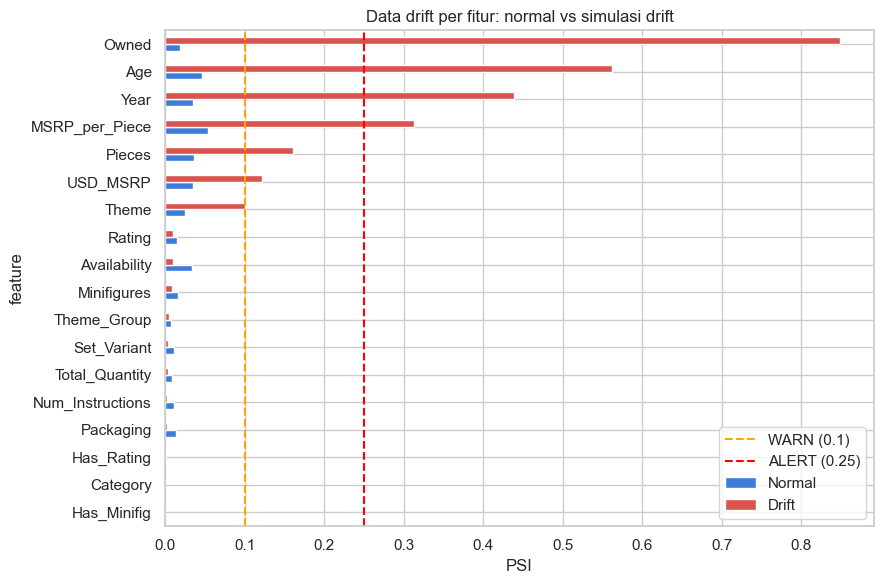

In [31]:
###Simulasi drift###
def make_drifted(X_, seed=0):
    rng = np.random.default_rng(seed)
    d = X_.copy()
    d["Pieces"] = d["Pieces"] * 1.6
    d["USD_MSRP"] = d["USD_MSRP"] * 1.35
    d["MSRP_per_Piece"] = d["USD_MSRP"] / d["Pieces"]
    d["Owned"] = d["Owned"] * 0.4
    d["Year"] = d["Year"] + 4
    d["Age"] = d["Age"] - 4
    d.loc[rng.random(len(d)) < 0.30, "Theme"] = "NewTheme 2027"
    d.loc[rng.random(len(d)) < 0.25, "Rating"] = np.nan
    return d

X_drift = make_drifted(X_test)
drift_shift = mon.drift_report(X_drift, reference)

cmp_df = (drift_normal.set_index("feature")[["psi"]].rename(columns={"psi": "Normal"})
          .join(drift_shift.set_index("feature")[["psi", "status", "unseen_rate", "missing_delta"]]
                .rename(columns={"psi": "Drift"}))
          .sort_values("Drift", ascending=False))
display(cmp_df.round(3))

fig, ax = plt.subplots(figsize=(9, 6))
cmp_df[["Normal", "Drift"]].iloc[::-1].plot.barh(ax=ax, color=["#3b7dd8", "#d9534f"])
ax.axvline(mon.PSI_WARN, color="orange", ls="--", label=f"WARN ({mon.PSI_WARN})")
ax.axvline(mon.PSI_ALERT, color="red", ls="--", label=f"ALERT ({mon.PSI_ALERT})")
ax.set_xlabel("PSI"); ax.set_title("Data drift per fitur: normal vs simulasi drift"); ax.legend()
plt.tight_layout(); plt.show()

**8. Simulasi penurunan performa (concept drift).** Harga pasar bisa naik meski fitur set tidak berubah, misalnya karena koleksi sedang tren. Itu tidak terdeteksi oleh drift fitur, hanya terlihat saat harga aktual dibandingkan dengan prediksi. Simulasi: 6 jendela waktu, harga aktual dinaikkan bertahap (0%, 0%, 0%, 15%, 30%, 50%) terhadap prediksi model yang sama.

,n,inflasi_pasar,rmse_log,rmse_ratio,bias_log,mae_usd
window,,,,,,
W1,182,+0%,0.430,0.894,-0.018,19.584
W2,182,+0%,0.497,1.033,0.063,44.819
W3,182,+0%,0.529,1.101,-0.040,41.461
W4,181,+15%,0.544,1.130,0.075,65.176
W5,181,+30%,0.507,1.054,0.248,51.831
W6,181,+50%,0.575,1.194,0.381,63.305


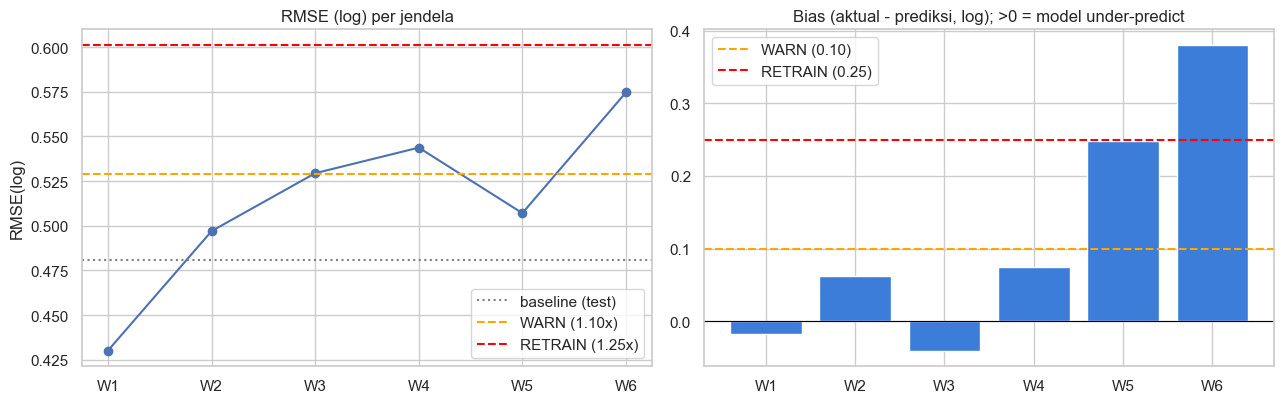

In [32]:
###Simulasi performa per jendela waktu###
rng = np.random.default_rng(7)
order = rng.permutation(len(X_test))
windows = np.array_split(order, 6)
inflation = [1.00, 1.00, 1.00, 1.15, 1.30, 1.50]

base = test_row["RMSE(log)"]
rows = []
for w, (ids, f) in enumerate(zip(windows, inflation), 1):
    y_true = y_test.iloc[ids].values + np.log(f)          # harga aktual yang sudah naik
    y_hat = final_model.predict(X_test.iloc[ids])
    p = mon.performance_report(y_true, y_hat)
    p.update(window=f"W{w}", inflasi_pasar=f"+{(f-1)*100:.0f}%", rmse_ratio=p["rmse_log"] / base)
    rows.append(p)
perf_win = pd.DataFrame(rows).set_index("window")
display(perf_win[["n", "inflasi_pasar", "rmse_log", "rmse_ratio", "bias_log", "mae_usd"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(perf_win.index, perf_win["rmse_log"], marker="o")
axes[0].axhline(base, color="gray", ls=":", label="baseline (test)")
axes[0].axhline(base * 1.10, color="orange", ls="--", label="WARN (1.10x)")
axes[0].axhline(base * 1.25, color="red", ls="--", label="RETRAIN (1.25x)")
axes[0].set(title="RMSE (log) per jendela", ylabel="RMSE(log)"); axes[0].legend()
axes[1].bar(perf_win.index, perf_win["bias_log"], color="#3b7dd8")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].axhline(0.10, color="orange", ls="--", label="WARN (0.10)")
axes[1].axhline(0.25, color="red", ls="--", label="RETRAIN (0.25)")
axes[1].legend()
axes[1].set(title="Bias (aktual - prediksi, log); >0 = model under-predict")
plt.tight_layout(); plt.show()

In [33]:
###Keputusan monitoring per skenario###
scenarios = {
    "Normal (log API)":                         (drift_normal, perf_normal),
    "Drift fitur saja":                         (drift_shift, None),
    "Concept drift saja (W6, fitur normal)":    (drift_normal, perf_win.loc["W6"].to_dict()),
    "Drift fitur + performa turun (W6)":        (drift_shift, perf_win.loc["W6"].to_dict()),
}
for name, (d, p) in scenarios.items():
    res = mon.overall_status(d, p, base)
    print(f"{name:42s} -> {res['status']:8s} {'; '.join(res['reasons'])}")

Normal (log API)                           -> OK       
Drift fitur saja                           -> ALERT    4 fitur drift berat (PSI>=0.25); 4 fitur drift ringan/data quality
Concept drift saja (W6, fitur normal)      -> RETRAIN  RMSE(log) 1.19x baseline; bias +0.38 (log) signifikan
Drift fitur + performa turun (W6)          -> RETRAIN  4 fitur drift berat (PSI>=0.25); 4 fitur drift ringan/data quality; RMSE(log) 1.19x baseline; bias +0.38 (log) signifikan


**9. Rencana operasional monitoring**

| Yang dipantau | Cara | Frekuensi | WARN | Tindakan |
|---|---|---|---|---|
| Kesehatan service | `GET /health`, error rate & latensi | Real-time | Error > 1% | Cek log, rollback versi |
| Data quality | Missing rate, nilai di luar p1–p99, kategori baru | Harian | Missing naik > 10 poin; kategori baru > 5% | Cek sumber data |
| Data drift | PSI per fitur vs data training | Mingguan | PSI ≥ 0.10 | **ALERT** bila ≥ 0.25: investigasi, percepat pengumpulan harga aktual |
| Performa | RMSE(log) dan bias dari `/feedback` | Mingguan / saat aktual masuk | RMSE ≥ 1.10x baseline atau bias ≥ 0.10 | **RETRAIN** bila RMSE ≥ 1.25x atau bias ≥ 0.25 |
| Keputusan | `overall_status()` | Mingguan | — | RETRAIN: latih ulang data terbaru, validasi, naikkan `model_version` |

Catatan yang perlu dipertimbangkan sebelum produksi nyata:
- Ambang (PSI 0.10/0.25, RMSE 1.10x/1.25x) adalah konvensi umum, **bukan hasil kalibrasi** pada data ini. Sesuaikan setelah ada beberapa minggu data nyata agar tidak terlalu berisik.
- Harga aktual tertunda, jadi drift fitur adalah peringatan dini, performa adalah konfirmasi.
- Bias dipantau terpisah dari RMSE: pada simulasi di atas, kenaikan harga +50% hanya menaikkan RMSE sekitar 1.2x, tetapi bias terlihat jelas.
- Jendela kecil itu berisik. Pada simulasi, W3 melewati 1.10x padahal tidak ada pergeseran. Gunakan jendela minimal ±300 baris dan jangan retrain dari satu jendela saja; tunggu 2 jendela berturut-turut.
- Log JSONL cukup untuk skala kecil; untuk trafik besar pindahkan ke database/object storage.
- Retraining sebaiknya diikuti validasi ulang dan perbandingan dengan model yang sedang live sebelum diganti (champion/challenger).

In [34]:
%%writefile README.md
# LEGO Price Predictor

Prediksi harga pasar set LEGO (Current_Price) dengan HistGradientBoosting,
lengkap dengan API FastAPI (deployment) dan monitoring drift/performa.

## Isi
- `Lego_set_and_prices_full.ipynb` - analisis, model, deployment, monitoring
- `deployment/` - API, modul fitur, modul monitoring, model tersimpan
- `sets.csv` - data

## Cara menjalankan
1. Taruh notebook dan `sets.csv` di folder yang sama.
2. Jalankan sel instalasi: `pip install fastapi uvicorn httpx pydantic joblib scipy`
3. Kernel -> Restart & Run All.

## Data
Dataset `sets.csv` diambil dari Kaggle:
- Judul dataset: LEGO Sets and Prices Over Time
- Pembuat: Alex Racape
- Link: https://www.kaggle.com/datasets/alexracape/lego-sets-and-prices-over-time
- Lisensi: MIT

Writing README.md
